In [6]:
import random
import matplotlib.pyplot as plt
from IPython.display import clear_output

In [29]:
rows = 4
cols = 4
startstate = (0,0)
goalstate = (3,3)
restricted = [
    (1,1), (2,2)
]
alpha = 0.1
epsilon = 0.2
episodes = 1000
display = [1,500,1000]
actions = {"UP": (-1,0), "DOWN": (1,0), "RIGHT": (0,1), "LEFT": (0,-1)}
action_names = list(actions.keys())

In [8]:
#V(s) - value of state s
v = {}
for r in range(rows):
  for c in range(cols):
    state = (r,c)
    if state not in restricted:
      v[state] = 0.0
v[goalstate] = 0.0

In [9]:
#function to move agent
def move_agent(state, action):
  r,c = state
  ar, ac = actions[action]
  nextstate = (r+ar, c+ac)
  if not (0<= nextstate[0]< rows and 0<=nextstate[1] < cols): #out of boundary
    return state
  if nextstate in restricted: #in restricted
    return state
  return nextstate

In [10]:
#function for random selection
def random_action():
  return random.choice(action_names)
#display
def display_grid(agent_position, episode, step):
    print("\nGrid World")
    print("Episode:", episode, " Step:", step)
    for row in range(rows):
        for col in range(cols):
            state = (row, col)
            if state == agent_position:
                print(" A ", end=" | ")
            elif state == startstate:
                print(" S ", end=" | ")
            elif state == goalstate:
                print(" G ", end=" | ")
            elif state in restricted:
                print(" X ", end=" | ")
            else:
                print(" . ", end=" | ")

        print()

    print("S = Start")
    print("A = Agent")
    print("X = Restricted State")
    print("G = Goal")

#visualization of grid
def visualize_grid(agent_position, episode, step):

    clear_output(wait=True)
    fig, ax = plt.subplots(figsize=(5, 5))

    ax.set_xlim(-0.5, cols - 0.5)
    ax.set_ylim(-0.5, rows - 0.5)

    ax.set_xticks(range(cols))
    ax.set_yticks(range(rows))

    ax.grid(True)

    # Display all restricted states
    for restricted_state in restricted:
        x = restricted_state[1]
        y = rows - 1 - restricted_state[0]

        ax.text(
            x, y, "X",
            fontsize=20,
            ha="center",
            va="center"
        )

    # Start
    start_x = startstate[1]
    start_y = rows - 1 - startstate[0]

    ax.text(
        start_x, start_y, "S",
        fontsize=20,
        ha="center",
        va="center"
    )

    # Goal
    goal_x = goalstate[1]
    goal_y = rows - 1 - goalstate[0]

    ax.text(
        goal_x, goal_y, "G",
        fontsize=20,
        ha="center",
        va="center"
    )

    # Agent
    agent_x = agent_position[1]
    agent_y = rows - 1 - agent_position[0]

    ax.plot(
        agent_x,
        agent_y,
        "o",
        markersize=20
    )

    ax.set_title(
        f"Grid World — Episode {episode}, Step {step}"
    )

    plt.show(block=False)
    plt.pause(0.3)
    plt.close()

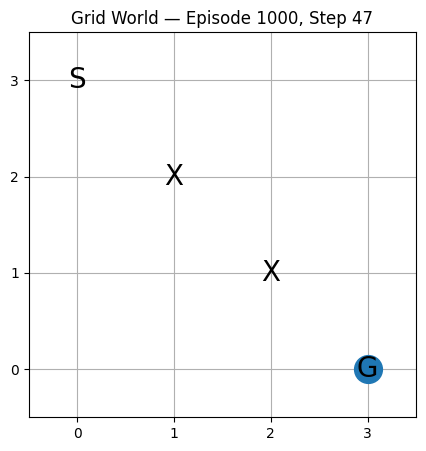


EPISODE COMPLETED
Episode: 1000
Total Steps: 47

Complete Agent Movement:
0: (0, 0) START
1: (0, 0) START
2: (0, 1) 
3: (0, 0) START
4: (0, 0) START
5: (0, 0) START
6: (0, 0) START
7: (1, 0) 
8: (2, 0) 
9: (2, 1) 
10: (2, 1) 
11: (3, 1) 
12: (3, 2) 
13: (3, 2) 
14: (3, 2) 
15: (3, 1) 
16: (3, 1) 
17: (3, 1) 
18: (3, 1) 
19: (2, 1) 
20: (3, 1) 
21: (3, 2) 
22: (3, 1) 
23: (2, 1) 
24: (2, 1) 
25: (2, 1) 
26: (2, 1) 
27: (2, 1) 
28: (2, 0) 
29: (2, 1) 
30: (3, 1) 
31: (3, 0) 
32: (2, 0) 
33: (2, 1) 
34: (2, 1) 
35: (3, 1) 
36: (3, 2) 
37: (3, 2) 
38: (3, 2) 
39: (3, 1) 
40: (3, 0) 
41: (3, 1) 
42: (3, 2) 
43: (3, 2) 
44: (3, 2) 
45: (3, 1) 
46: (3, 2) 
47: (3, 3) GOAL

Training Completed!


In [11]:
# training with random selection
# TD error: delta = reward(received for moving to next state) + V(st+1)(updated estimate of how good next state is) - V(st)(old guess of how good current state is)
# V(st) = V(st) + alpha * delta
for ep in range(1, episodes + 1):
    state = startstate
    trajectory = [state]  # to track every step agent took
    detailed_display = ep in display
    if detailed_display:
        print("\n" + "=" * 70)
        print("EPISODE:", ep)
        print("=" * 70)
    step = 0
    while state != goalstate:
        step += 1
        action = random_action()
        nextstate = move_agent(state, action)
        if nextstate == goalstate:
            reward = 1
        else:
            reward = 0

        oldvalue = v[state]
        tderror = reward + v[nextstate] - v[state]
        v[state] = v[state] + alpha * tderror
        trajectory.append(nextstate)
        if detailed_display:
            print("\nStep:", step)
            print("Current State (St):", state)
            print("Action:", action)
            print("Reward (Rt+1):", reward)
            print("Next State (St+1):", nextstate)
            print("Old V(St):", round(oldvalue, 4))
            print("V(St+1):", round(v[nextstate], 4))
            print("TD Error:", round(tderror, 4))
            print("Updated V(St):", round(v[state], 4))

            display_grid(nextstate, ep, step)
            visualize_grid(nextstate, ep, step)
        state = nextstate

    if detailed_display:
        print("\n" + "=" * 70)
        print("EPISODE COMPLETED")
        print("=" * 70)

        print("Episode:", ep)
        print("Total Steps:", step)

        print("\nComplete Agent Movement:")

        for i, position in enumerate(trajectory):
            if position == startstate:
                label = "START"
            elif position == goalstate:
                label = "GOAL"
            else:
                label = ""

            print(f"{i}: {position} {label}")

print("\nTraining Completed!")


In [ ]:
#final state value function
print("\n" + "=" * 70)
print("FINAL STATE-VALUE FUNCTION")
print("=" * 70)

for row in range(rows):

    for col in range(cols):

        state = (row, col)

        if state in restricted:
            print(f"{'X':>8}", end=" ")
        else:
            print(
                f"{v[state]:8.4f}",
                end=" "
            )

    print()



FINAL STATE-VALUE FUNCTION
  1.0000   1.0000   1.0000   1.0000 
  1.0000        X   1.0000   1.0000 
  1.0000   1.0000        X   1.0000 
  1.0000   1.0000   1.0000   0.0000 


In [ ]:
#value function grid
print("\nValue Function Grid:")

for row in range(rows):

    for col in range(cols):

        state = (row, col)

        if state == startstate:
            print(
                f"[ S:{v[state]:.2f} ]",
                end=" "
            )

        elif state == goalstate:
            print(
                "[  GOAL  ]",
                end=" "
            )

        elif state in restricted:
            print(
                "[   X    ]",
                end=" "
            )

        else:
            print(
                f"[ {v[state]:.2f} ]",
                end=" "
            )

    print()


Value Function Grid:
[ S:1.00 ] [ 1.00 ] [ 1.00 ] [ 1.00 ] 
[ 1.00 ] [   X    ] [ 1.00 ] [ 1.00 ] 
[ 1.00 ] [ 1.00 ] [   X    ] [ 1.00 ] 
[ 1.00 ] [ 1.00 ] [ 1.00 ] [  GOAL  ] 


In [35]:
epsilon = 0.1

In [36]:
#with epsilon
def random_action_epsilon():
  if random.random() < epsilon:
    action = random.choice(action_names)
    return action
  else:
    #EXPLOIT: Look ahead at the value of neighboring states and choose the best one
    best_action = None
    best_value = -float('inf')

    for a in action_names:
        resulting_state = move_agent(state, a)

        # Look up the learned value of that potential next state
        state_value = v[resulting_state]

        # Track the action that leads to the highest-value state
        if state_value > best_value:
            best_value = state_value
            best_action = a

    action = best_action
    return  action

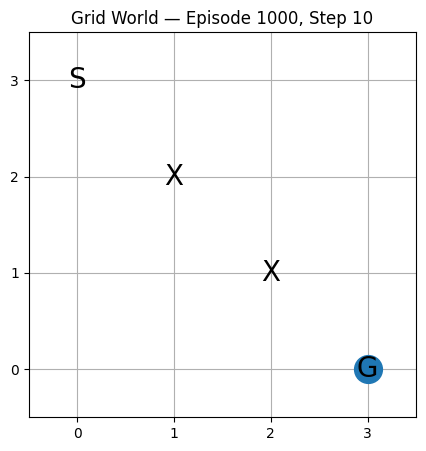


EPISODE COMPLETED
Episode: 1000
Total Steps: 10

Complete Agent Movement:
0: (0, 0) START
1: (0, 1) 
2: (0, 2) 
3: (0, 3) 
4: (1, 3) 
5: (2, 3) 
6: (2, 3) 
7: (2, 3) 
8: (2, 3) 
9: (2, 3) 
10: (3, 3) GOAL

Training Completed!


In [37]:
# training with random selection
# TD error: delta = reward(received for moving to next state) + V(st+1)(updated estimate of how good next state is) - V(st)(old guess of how good current state is)
# V(st) = V(st) + alpha * delta
for ep in range(1, episodes + 1):
    state = startstate
    trajectory = [state]  # to track every step agent took
    detailed_display = ep in display
    if detailed_display:
        print("\n" + "=" * 70)
        print("EPISODE:", ep)
        print("=" * 70)
    step = 0
    while state != goalstate:
        step += 1
        action = random_action_epsilon()
        nextstate = move_agent(state, action)
        if nextstate == goalstate:
            reward = 1
        else:
            reward = 0

        oldvalue = v[state]
        tderror = reward + v[nextstate] - v[state]
        v[state] = v[state] + alpha * tderror
        trajectory.append(nextstate)
        if detailed_display:
            print("\nStep:", step)
            print("Current State (St):", state)
            print("Action:", action)
            print("Reward (Rt+1):", reward)
            print("Next State (St+1):", nextstate)
            print("Old V(St):", round(oldvalue, 4))
            print("V(St+1):", round(v[nextstate], 4))
            print("TD Error:", round(tderror, 4))
            print("Updated V(St):", round(v[state], 4))

            display_grid(nextstate, ep, step)
            visualize_grid(nextstate, ep, step)
        state = nextstate

    if detailed_display:
        print("\n" + "=" * 70)
        print("EPISODE COMPLETED")
        print("=" * 70)

        print("Episode:", ep)
        print("Total Steps:", step)

        print("\nComplete Agent Movement:")

        for i, position in enumerate(trajectory):
            if position == startstate:
                label = "START"
            elif position == goalstate:
                label = "GOAL"
            else:
                label = ""

            print(f"{i}: {position} {label}")

print("\nTraining Completed!")


In [44]:
epsilon = 0.5

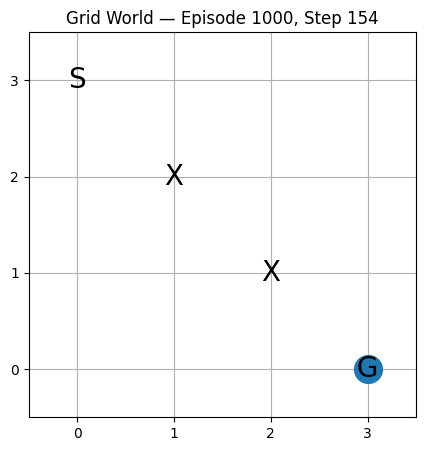


EPISODE COMPLETED
Episode: 1000
Total Steps: 154

Complete Agent Movement:
0: (0, 0) START
1: (0, 1) 
2: (0, 2) 
3: (0, 3) 
4: (1, 3) 
5: (2, 3) 
6: (2, 3) 
7: (2, 3) 
8: (2, 3) 
9: (2, 3) 
10: (2, 3) 
11: (2, 3) 
12: (2, 3) 
13: (2, 3) 
14: (2, 3) 
15: (2, 3) 
16: (2, 3) 
17: (2, 3) 
18: (2, 3) 
19: (2, 3) 
20: (2, 3) 
21: (2, 3) 
22: (2, 3) 
23: (2, 3) 
24: (2, 3) 
25: (2, 3) 
26: (2, 3) 
27: (2, 3) 
28: (2, 3) 
29: (2, 3) 
30: (2, 3) 
31: (2, 3) 
32: (2, 3) 
33: (2, 3) 
34: (2, 3) 
35: (2, 3) 
36: (2, 3) 
37: (2, 3) 
38: (2, 3) 
39: (2, 3) 
40: (2, 3) 
41: (2, 3) 
42: (2, 3) 
43: (2, 3) 
44: (2, 3) 
45: (2, 3) 
46: (2, 3) 
47: (2, 3) 
48: (2, 3) 
49: (2, 3) 
50: (2, 3) 
51: (2, 3) 
52: (2, 3) 
53: (2, 3) 
54: (2, 3) 
55: (2, 3) 
56: (2, 3) 
57: (2, 3) 
58: (2, 3) 
59: (2, 3) 
60: (2, 3) 
61: (2, 3) 
62: (2, 3) 
63: (2, 3) 
64: (2, 3) 
65: (2, 3) 
66: (2, 3) 
67: (2, 3) 
68: (2, 3) 
69: (2, 3) 
70: (2, 3) 
71: (2, 3) 
72: (2, 3) 
73: (2, 3) 
74: (2, 3) 
75: (2, 3) 
76: (2, 3) 
77: (

In [46]:
#with epsilon decay
# training with random selection
# TD error: delta = reward(received for moving to next state) + V(st+1)(updated estimate of how good next state is) - V(st)(old guess of how good current state is)
# V(st) = V(st) + alpha * delta
for ep in range(1, episodes + 1):
    state = startstate
    trajectory = [state]  # to track every step agent took
    detailed_display = ep in display
    if detailed_display:
        print("\n" + "=" * 70)
        print("EPISODE:", ep)
        print("=" * 70)
    step = 0
    while state != goalstate:
        step += 1
        action = random_action_epsilon()
        nextstate = move_agent(state, action)
        if nextstate == goalstate:
            reward = 1
        else:
            reward = 0

        oldvalue = v[state]
        tderror = reward + v[nextstate] - v[state]
        v[state] = v[state] + alpha * tderror
        trajectory.append(nextstate)
        if detailed_display:
            print("\nStep:", step)
            print("Current State (St):", state)
            print("Action:", action)
            print("Reward (Rt+1):", reward)
            print("Next State (St+1):", nextstate)
            print("Old V(St):", round(oldvalue, 4))
            print("V(St+1):", round(v[nextstate], 4))
            print("TD Error:", round(tderror, 4))
            print("Updated V(St):", round(v[state], 4))

            display_grid(nextstate, ep, step)
            visualize_grid(nextstate, ep, step)
        state = nextstate

    if detailed_display:
        print("\n" + "=" * 70)
        print("EPISODE COMPLETED")
        print("=" * 70)

        print("Episode:", ep)
        print("Total Steps:", step)

        print("\nComplete Agent Movement:")

        for i, position in enumerate(trajectory):
            if position == startstate:
                label = "START"
            elif position == goalstate:
                label = "GOAL"
            else:
                label = ""

            print(f"{i}: {position} {label}")
    # Decay epsilon after each episode completes
    epsilon = max(0.05, epsilon * 0.99)

print("\nTraining Completed!")
